# Preprocessing and clustering

In [1]:
from __future__ import annotations # 类型注解，-> 表示返回值类型,: 表示参数类型
import anndata as ad
import scanpy as sc
import pooch # pooch包将模型数据下载到本地

In [2]:
sc.settings.set_figure_params(dpi = 50, facecolor = 'white') # 设置全局绘图参数，分辨率50，背景色为白色

数据说明：采集自健康人类供者的骨髓单个核细胞，是 [Open Problems 的 NeurIPS 2021 基准评测数据集](https://openproblems.bio/competitions/neurips_2021/)的一部分（Luecken2021）。

样本使用 10X Multiome Gene Expression and Chromatin Accessibility 试剂盒测量，同时检测基因表达与染色质可及性。

In [3]:
EXAMPLE_DATA = pooch.create(    # pooch.create()创建一个pooch对象,用于数据管理,全大写一般表示全局静态变量
    path = pooch.os_cache("scanpy_learn"), # 在操作系统创建一个叫scanpy_learn的缓存目录
    base_url = "doi:10.6084/m9.figshare.22716739.v1/" # 数据文件的基础网络地址
)
# load_registry_from_doi()让pooch对象知道有哪些文件
EXAMPLE_DATA.load_registry_from_doi() 

In [4]:
EXAMPLE_DATA.registry # 查看登记的文件

{'s1d1_filtered_feature_bc_matrix.h5': 'md5:a99285913ea3f3d22600d3d2f8a88e34',
 's1d3_filtered_feature_bc_matrix.h5': 'md5:825f7f7578e3dc0b8955f5a97a402338'}

In [5]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": 's1d3_filtered_feature_bc_matrix.h5'
}
adatas = {}
for sample_name, sample_filename in samples.items():
    path = EXAMPLE_DATA.fetch(sample_filename) # 根据文件名从EXAMPLE_DATA中获取文件的路径（如果没有自动下载）
    sample_adata = sc.read_10x_h5(path) # 根据路径读取一个10x Genomics格式的.h5单细胞数据文件
    sample_adata.var_names_make_unique() # 将读取到的重复名称处理为唯一名字（加标记）
    adatas[sample_name] = sample_adata # 存入字典

adata = ad.concat(adatas, label="sample") # 将s1d1和s1d3的矩阵数据拼接，添加一列标签sample记录来源是s1d1还是s1d3
adata.obs_names_make_unique() 
# AnnData矩阵中obs对应细胞也就是行信息，var对应基因也就是列信息
# 拼接后可能产生相同的细胞名所以进行处理
print(adata.obs["sample"].value_counts()) # 从细胞信息表中选出sample列,统计两种sample的数量
adata

f:\anaconda\envs\pytorch\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
f:\anaconda\envs\pytorch\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


f:\anaconda\envs\pytorch\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
f:\anaconda\envs\pytorch\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
f:\anaconda\envs\pytorch\lib\site-packages\anndata\_core\anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'


### AnnData对象示意
         adata.X                            adata.obs

        GeneA GeneB GeneC                   sample  cell_type
Cell1     5     0     2             Cell1    s1d1    T cell
Cell2     0     8     1    ←对应→   Cell2    s1d1    B cell
Cell3     3     1     0             Cell3    s1d3    T cell
Cell4     0     6     2             Cell4    s1d3    Monocyte

## Quality Control

In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# 在基因信息表添加mt列，mt列的值为基因名是否以MT-开头（人类线粒体编码基因多以MT-开头，小鼠多以mt-开头）
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# 标记核糖体蛋白基因
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")
# 标记血细胞基因，选出HB开头且不是HBP开头的基因

In [7]:
# 计算QC指标
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars = ['mt','ribo','hb'], 
    inplace = True, # 直接将结果加入obs信息表中
    log1p = True # log(1+x)
)
# 统计的值包含每个细胞检测到的基因个数、基因的总表达量、mtr、ribo、hb三类基因在总表达量的占比、log1p计算
# 还有对于基因，在多少个细胞检测到，该基因的总表达量，平均表达量、有多少细胞没有检测到、lop1p计算

In [8]:
adata.obs.columns

Index(['sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts',
       'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mt',
       'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo',
       'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb',
       'log1p_total_counts_hb', 'pct_counts_hb'],
      dtype='object')

In [9]:
adata.var.columns

Index(['mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts',
       'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts',
       'log1p_total_counts'],
      dtype='object')

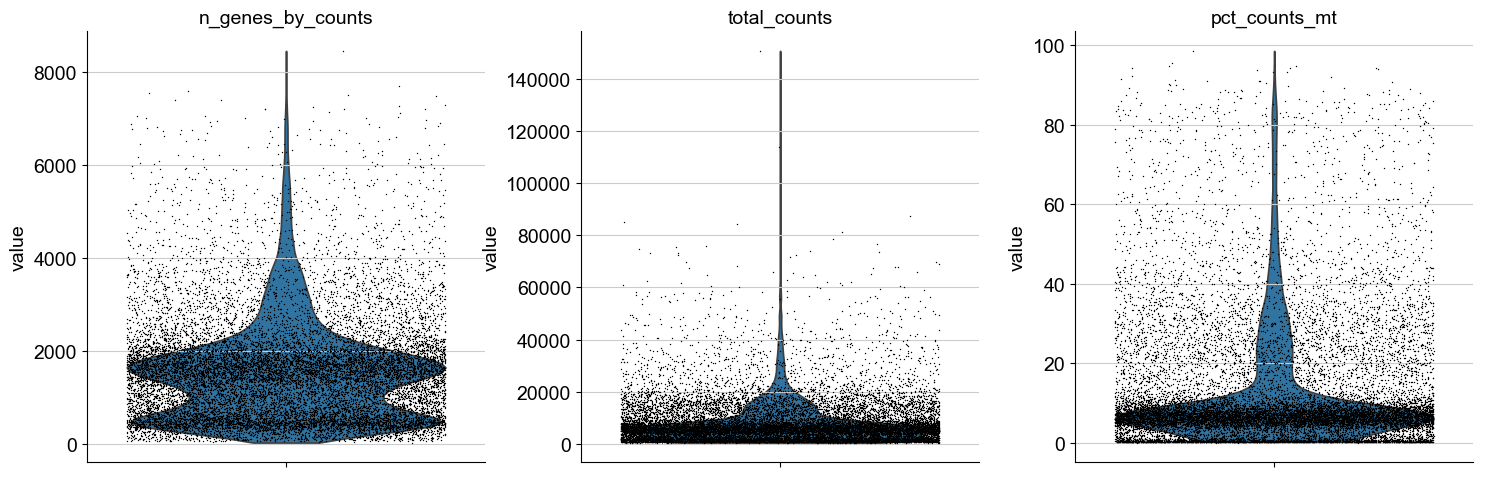

In [10]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"], # 要画的三个指标
    # 每个细胞检测到的基因种类数，每个细胞所有基因表达量，线粒体基因占总表达量
    jitter=0.4, # 让每个细胞对应的点横向抖动一定程度，减少重叠
    multi_panel=True, # 把不同指标分别放在独立的小面板中显示
)

这批数据的主体细胞 QC 指标总体集中，但存在明显的异常长尾。 大多数细胞检测到的基因数约在 几百至 2000 左右，但少量细胞达到 5000–8000+；total_counts 也存在少量极高值细胞，这些细胞可能需要警惕 doublet/multiplet。大多数细胞的线粒体基因比例 pct_counts_mt 较低，约集中在 5%–10%附近，但存在一批线粒体比例达到 20%–90% 的细胞，提示可能存在受损或低质量细胞。

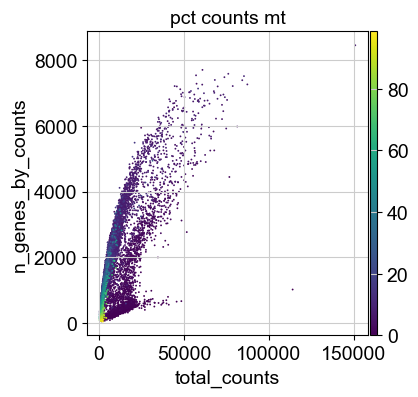

In [11]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt") # 绘制散点图
# 横轴total_counts：每个细胞的总counts/UMl数。
# 纵轴n_genes_by_counts ：每个细胞检测到的基因种类数。
# 颜色pct_counts_mt：每个细胞的线粒体基因counts 百分比.

counts 与基因数是否总体正相关，同时寻找高 counts/高基因数的疑似 doublet，以及线粒体比例异常高的疑似低质量细胞

In [12]:
# 过滤数据
sc.pp.filter_cells(adata, min_genes=100) # 删除检测到的基因数少于100个的细胞（异常细胞）
sc.pp.filter_genes(adata, min_cells=3) # 删除在少于3个细胞中被检测到的基因（无意义基因，减少运算）

### Doublet detection

In [ ]:
obs_df = adata.obs
vars_df = adata.var

In [14]:
# 检测双细胞
sc.pp.scrublet(adata,batch_key="sample") # 分别在s1d1和s1d3两个批次中检测双细胞
# batch_key相当于限定了算法进行的范围
# 需要scikit-image库

## Normalization
把总counts放缩到相同值，在此基础下把各基因表达量或细胞计数放缩
默认：放缩到counts中位数，CP10k：总counts统一到1w
CPM：总counts统一到1million

In [ ]:
# Saving count data
adata.layers["counts"] = adata.X.copy()
# adata.layers用于存储表达矩阵的各个版本，因为后续归一化会改变原矩阵中的数值
# 将细胞×基因的矩阵存到名为count的矩阵

In [17]:
sc.pp.normalize_total(adata) # 这里默认用中位数counts
sc.pp.log1p(adata) # 再进行一次log1p，压缩大数差距

## Feature selection
希望降低数据集的维度，仅保留信息量最大的基因

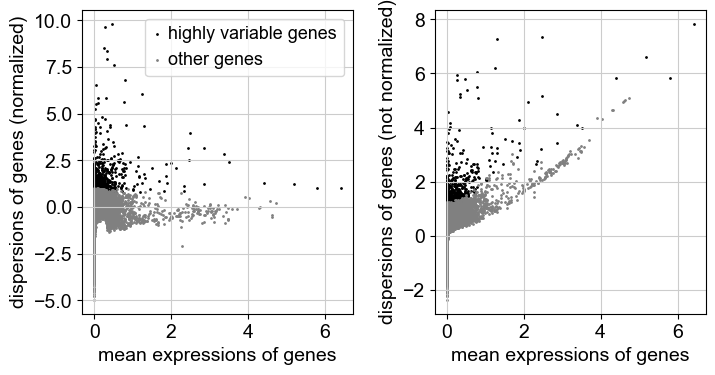

In [20]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
# 在考虑两种不同sample批次的情况下，筛选在不同细胞表达差异大的基因（高变基因）
sc.pl.highly_variable_genes(adata) # 绘制高变基因分布

筛选出的高变基因主要分布在标准化离散度较高的区域，而未入选基因的离散度总体较低。

## Dimensionality Reduction
通过主成分分析 (PCA) 来降低数据维度

In [21]:
sc.tl.pca(adata) # PCA
# 结果存储如下：
# adata.obsm["X_pca"]	每个细胞的 PCA 坐标
# adata.varm["PCs"]	各基因在主成分上的载荷（贡献权重）
# adata.uns["pca"]	各主成分的方差和方差解释比例等

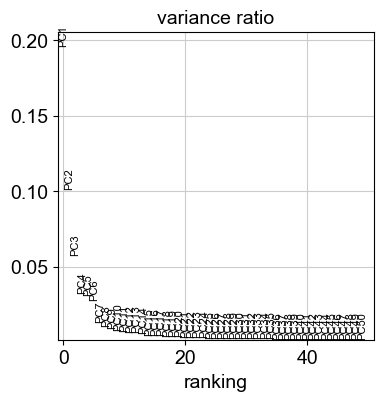

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50)
# 绘制前50个主成分的解释比例，加log=True用对数尺度绘图

观察此图前4~5个pc已经解释了绝大部分方差

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


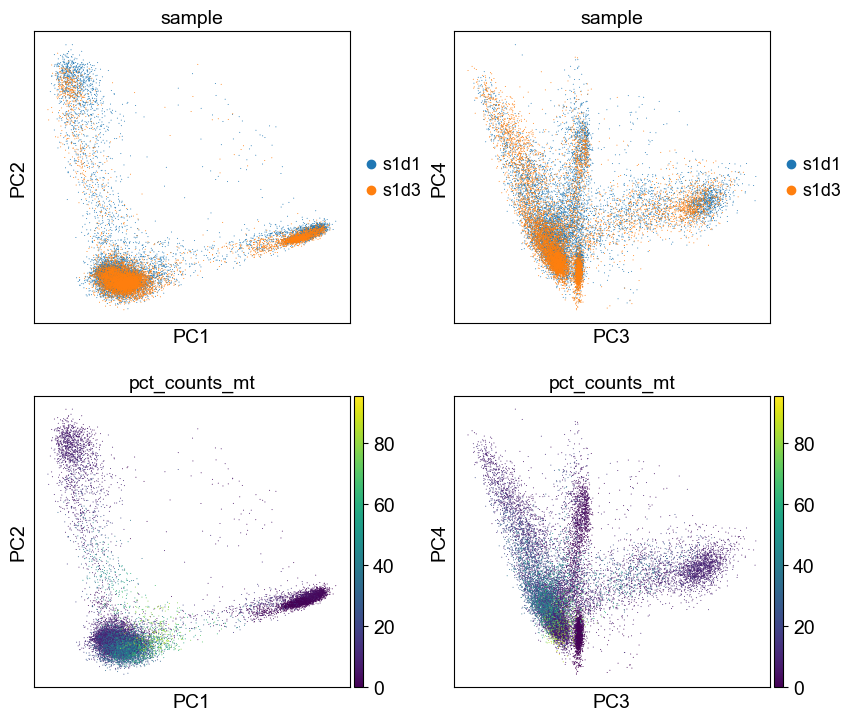

In [25]:
sc.pl.pca(
    adata,
    color = ["sample","sample","pct_counts_mt","pct_counts_mt"],
    # 按照来源s1d1 or s1d3着色
    # 按照每个细胞的线粒体基因比例着色
    dimensions = [(0,1),(2,3),(0,1),(2,3)],
    # (0,1)为PC1和PC2；(2,3)为PC3和PC4
    ncols = 2, # 每行两列图
    size = 2 # 控制散点大小
)

对不同sample，重叠度比较高，说明两个批次样本的基因表达量方差分布相近
对线粒体基因占比，左下角区域有一团明显的高占比低质量细胞，右边有一团明显的细胞聚类

## Nearest neighbor graph construction and visualization
构建细胞近邻图，并制作UMAP
PCA 和 UMAP 都能降维，但 PCA 更强调保留总体方差，UMAP 更强调保留局部邻域结构

In [ ]:
sc.pp.neighbors(adata)
# 保存数据如下
# adata.obsp["distances"] 细胞之间的近邻距离矩阵
# adata.obsp["connectivities"] 细胞之间的连接强度矩阵
# adata.uns["neighbors"] 近邻图的相关参数和信息

In [ ]:
sc.tl.umap(adata)
# 结果保存到adata.obsm["X_umap"]，是一个记录每个细胞以及umap二维坐标的矩阵

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


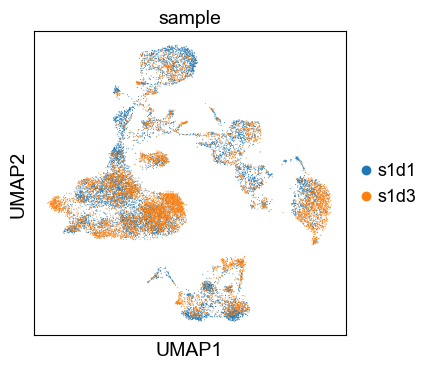

In [29]:
sc.pl.umap(
    adata,
    color = "sample",
    size = 2
)

蓝色和橙色分开程度说明了批次效应的强弱；蓝色、橙色在多数群体中混合说明没有明显的全局样本分离

In [ ]:
print(adata.obsm["X_pca"].shape)
print(adata.uns["neighbors"]["params"])
# 运行后说明计算近邻图时使用50个pc，邻域规模为15

(17041, 50)
{'n_neighbors': 15, 'method': 'umap', 'random_state': 0, 'metric': 'euclidean'}


## Clustering
Leiden 聚类

In [ ]:
sc.tl.leiden(adata,flavor="igraph",n_iterations = 2) # 迭代次数是2轮
# 之后在adata.obs["leiden"]显示聚类标签0，1，2，3...
# resolution可以控制聚类分辨率

In [32]:
adata.obs["leiden"].value_counts()

leiden
0     2057
7     1938
6     1622
8     1258
9     1088
1     1075
15    1059
17     908
14     833
11     668
5      628
22     506
18     488
20     477
12     457
13     388
2      364
3      310
10     307
19     148
16     107
4       84
23      72
25      72
24      66
21      61
Name: count, dtype: int64

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


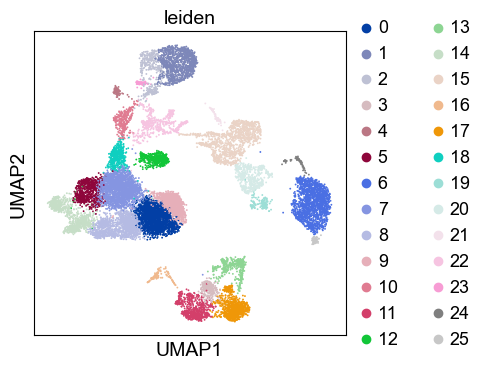

In [ ]:
sc.pl.umap(adata, color=['leiden']) # 根据聚类标签在UMAP标记

## Re-assess quality control and cell filtering
重新评估QC，因为在聚类的UMAP下更容易发现低质量细胞

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


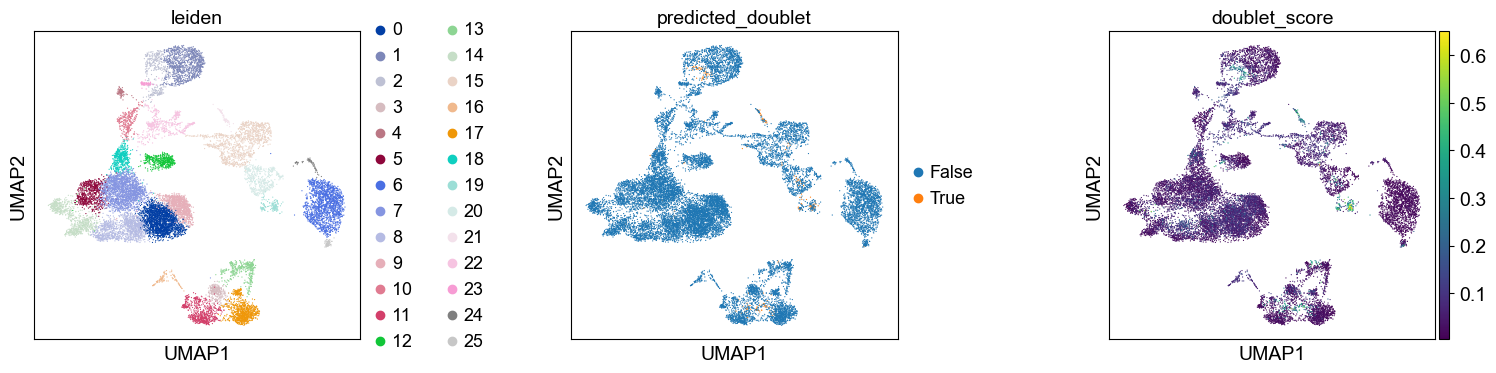

In [36]:
sc.pl.umap(
    adata,
    color = ["leiden","predicted_doublet","doublet_score"],
    wspace = 0.5, # 增加不同子图之间的水平间距
    size = 3
)

聚类里的19号聚类与高度怀疑的doublet细胞几乎重合，可能说明19号聚类不是一个真正的细胞类

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


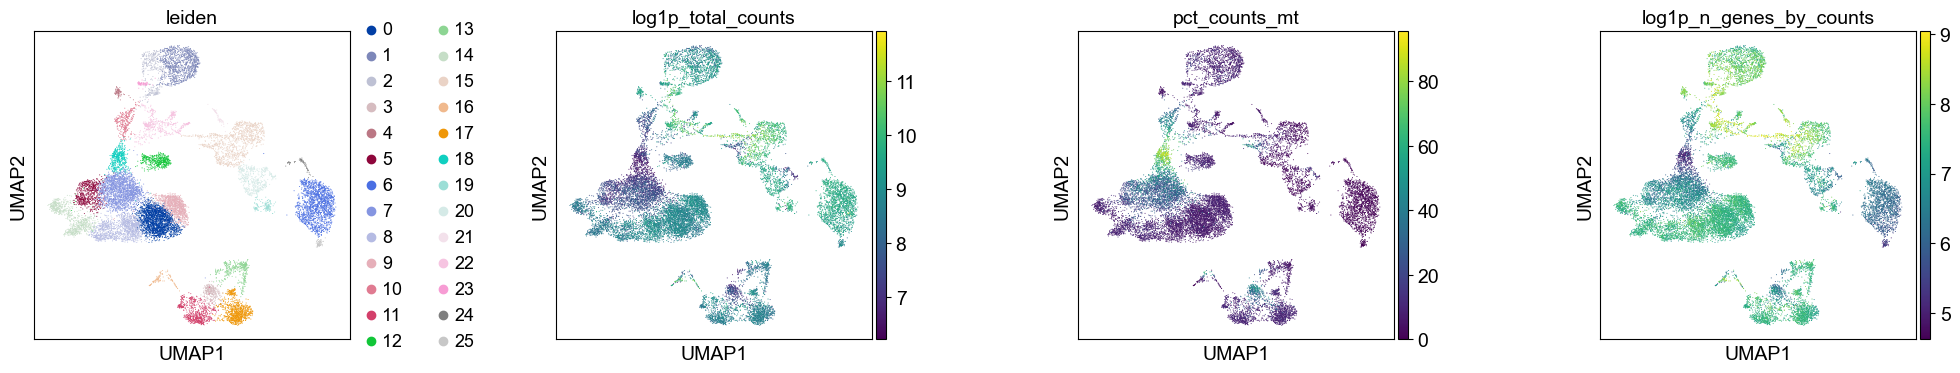

In [37]:
sc.pl.umap(
    adata,
    color = ["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace = 0.5, # 增加不同子图之间的水平间距
    size = 2
)

部分区域（18聚类附近）存在明显的线粒体比例升高、总counts和检测基因数偏低的现象，可能残留部分低质量细胞

## Manual cell-type annotation
细胞类型注释，通过聚类、识别marker基因、确定细胞类型

In [40]:
for res in [0.02,0.5,2.0]:
    sc.tl.leiden(adata,key_added=f"leiden_res_{res:4.2f}",resolution=res,flavor = "igraph")
    # key_added设置新三列保存聚类标签，4.2f表示保留2位小数宽度为4
    #adata.obs["leiden_res_0.02"]
    #adata.obs["leiden_res_0.50"]
    #adata.obs["leiden_res_2.00"]

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a fu

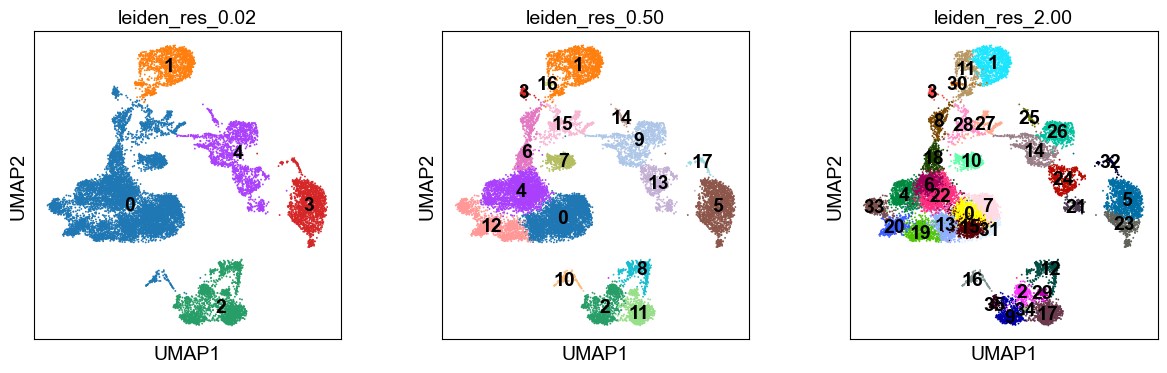

In [ ]:
# 看不同分辨率的聚类
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data", # 直接把聚类编号标注在 UMAP 图中的对应区域
)

## Marker gene set
人工细胞类型注释:已知细胞类型的Marker Genes → 查看各聚类的表达 → 判断细胞身份 → 添加注释

In [42]:
# 引入marker基因的字典，其中negative genes表示在该类细胞内表达少
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

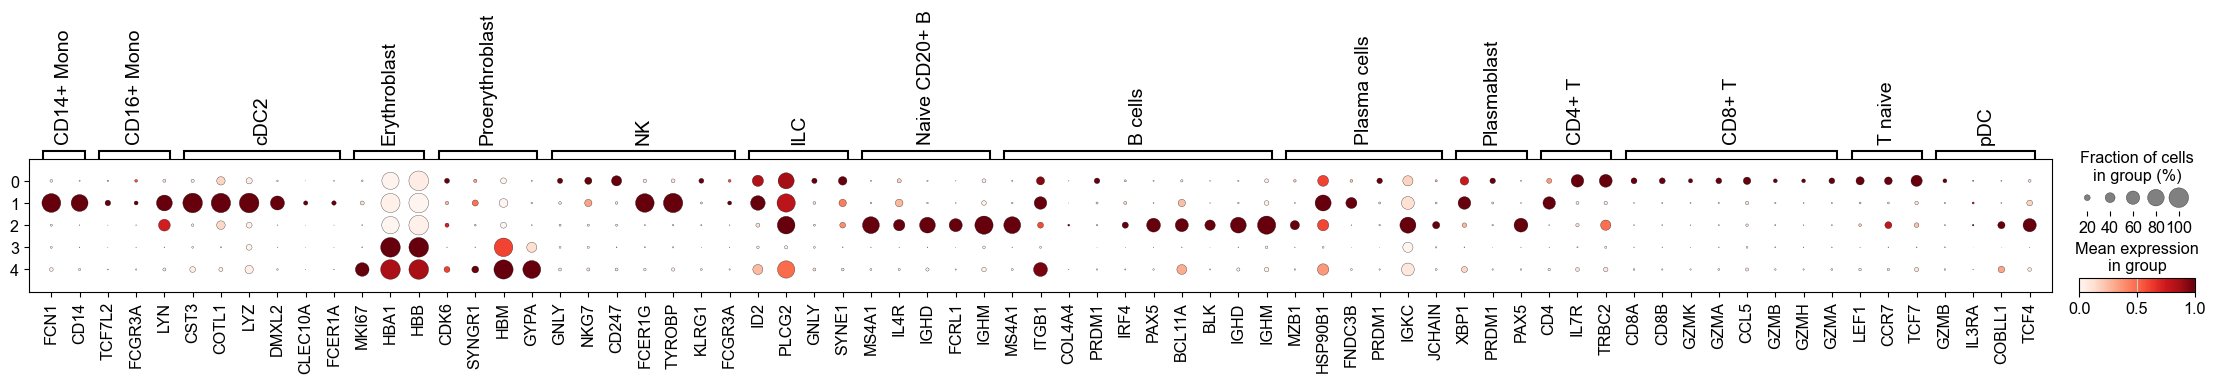

In [ ]:
sc.pl.dotplot(
    adata, 
    marker_genes, 
    groupby = 'leiden_res_0.02', # 以该分辨率下聚类结果绘制
    standard_scale = 'var' 
    # 某个基因在聚类a表达最低为min，在b表达最高为max
    # 将基因在各聚类的表达量[min,max]线性映射到[0,1]
    )

In [ ]:
# 根据上图进行细胞注释
adata.obs['cell_type_lvl1'] = adata.obs['leiden_res_0.02'].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "Erythroid",
        "3": "B Cells",
    }
)
# map()用于将字典中的键值对映射到'leiden_res_0.02'列的序号上
# 标签名lvl1表示是一级注释，可能还会有更细致亚型的注释

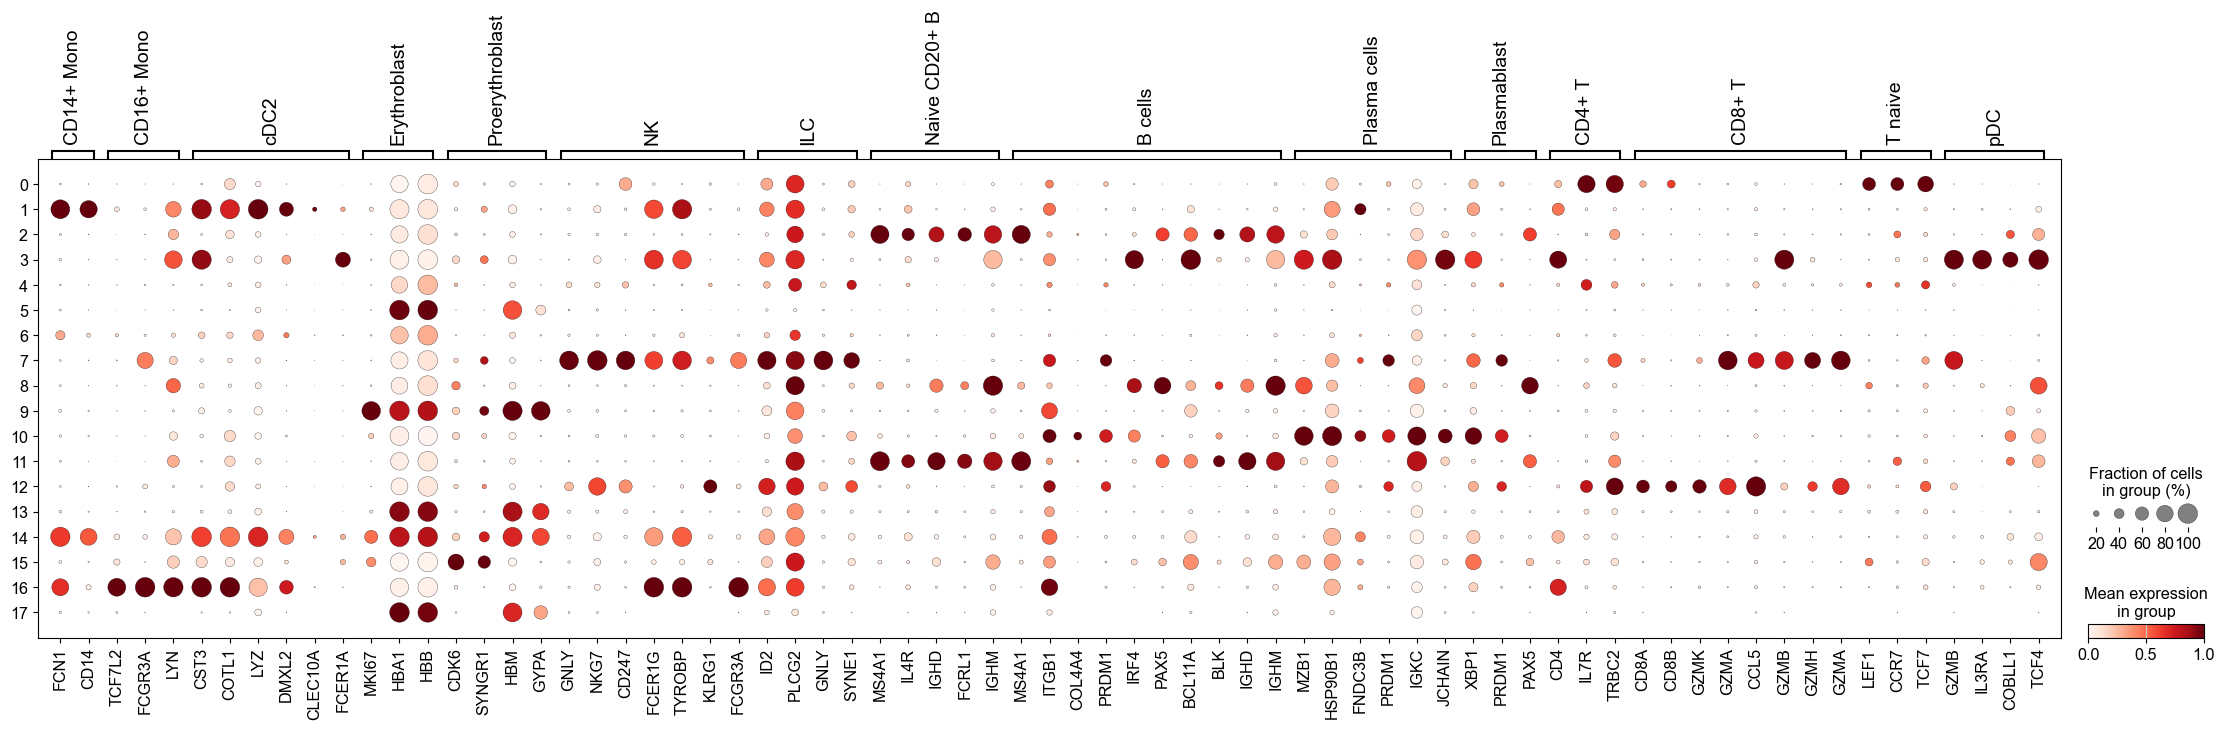

In [ ]:
# 换一个分辨率的聚类再做一次
sc.pl.dotplot(adata,marker_genes,groupby='leiden_res_0.50',standard_scale='var')

高分辨率之后基本能做到每个聚类能对应一个大类

# Differentially-expressed Genes as Markers
利用差异表达基因寻找各个细胞群的 Marker Genes，从而判断它们的生物学身份（相当于上一部分的逆向）

In [46]:
# 根据聚类，挑选每个聚类里的差异基因
sc.tl.rank_genes_groups(
    adata, 
    groupby = 'leiden_res_0.50', 
    method="wilcoxon") #  秩和检验，根据某基因在不同cluster表达量的排名挑选

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new impl

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new impl

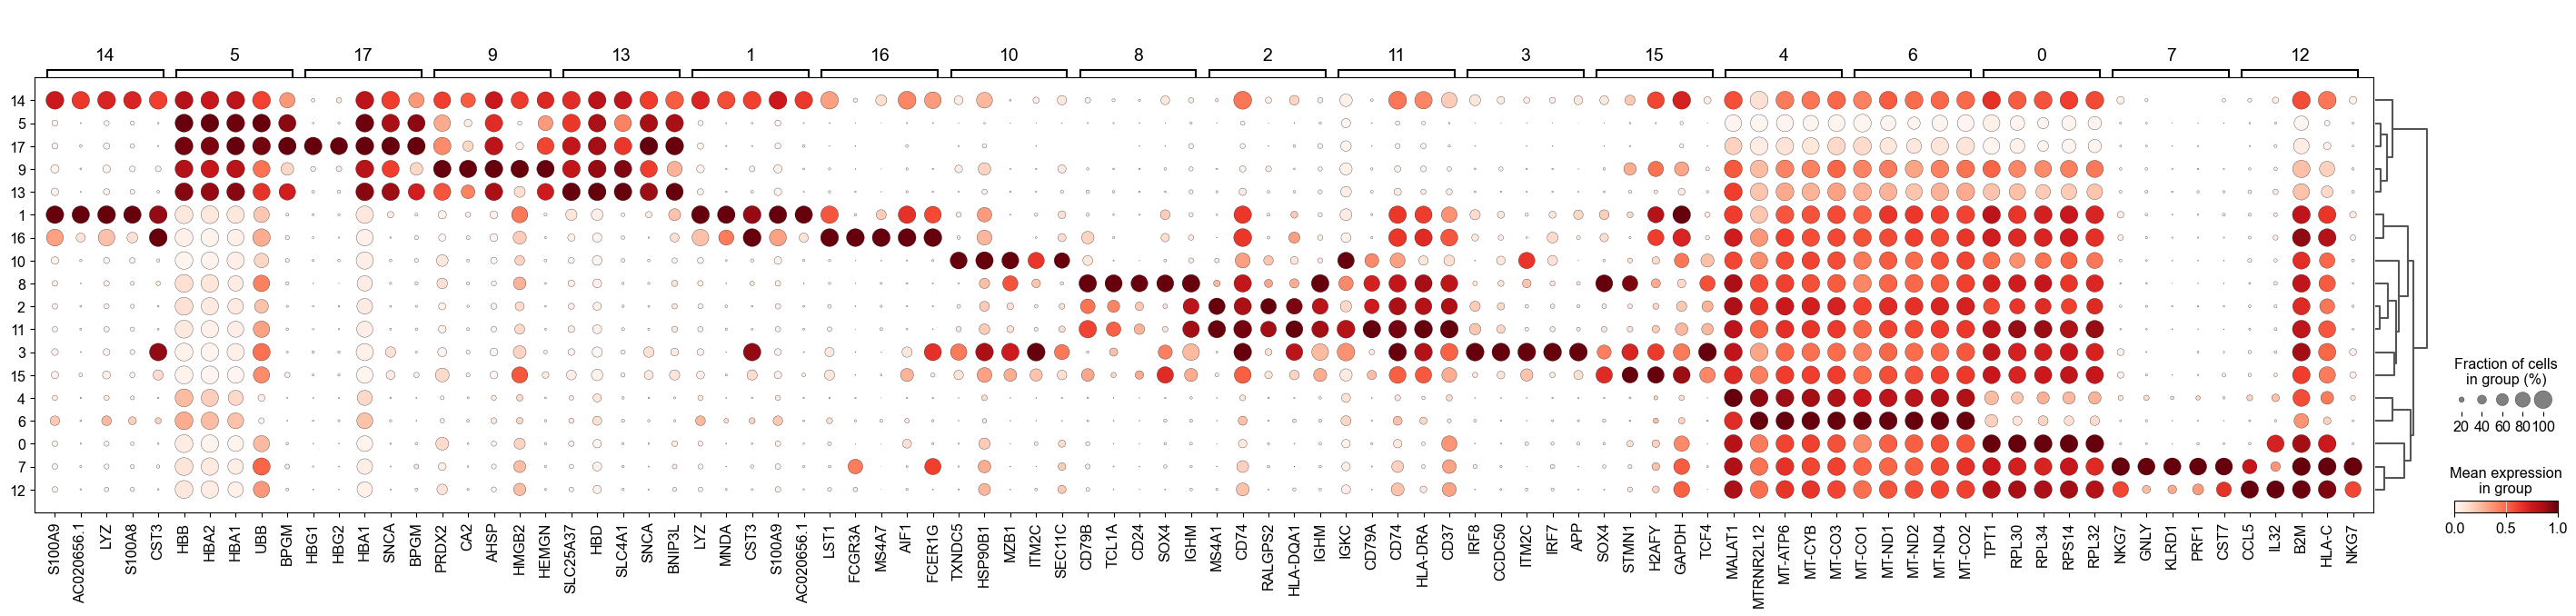

In [47]:
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby = "leiden_res_0.50",
    standard_scale = "var", 
    n_genes = 5
)# 这里绘图选用上一步挑选的每个cluster的前五个差异基因

In [48]:
# 将差异表达结果转换为 DataFrame
sc.get.rank_genes_groups_df(adata,group = "7").head(5)
# 获取cluster7的差异表达结果表格，只显示前五行

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()


,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.610233,6.547157,9.728576e-278,2.279114e-273
1,GNLY,33.932396,7.375255,2.218155e-252,2.598235e-248
2,KLRD1,33.903980,5.843249,5.819822e-252,4.544699e-248
3,PRF1,33.111065,5.437214,2.059603e-240,1.206258e-236
4,CST7,32.995819,5.224056,9.324716e-239,4.369003e-235


f:\anaconda\envs\pytorch\lib\site-packages\scanpy\get\get.py:86: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


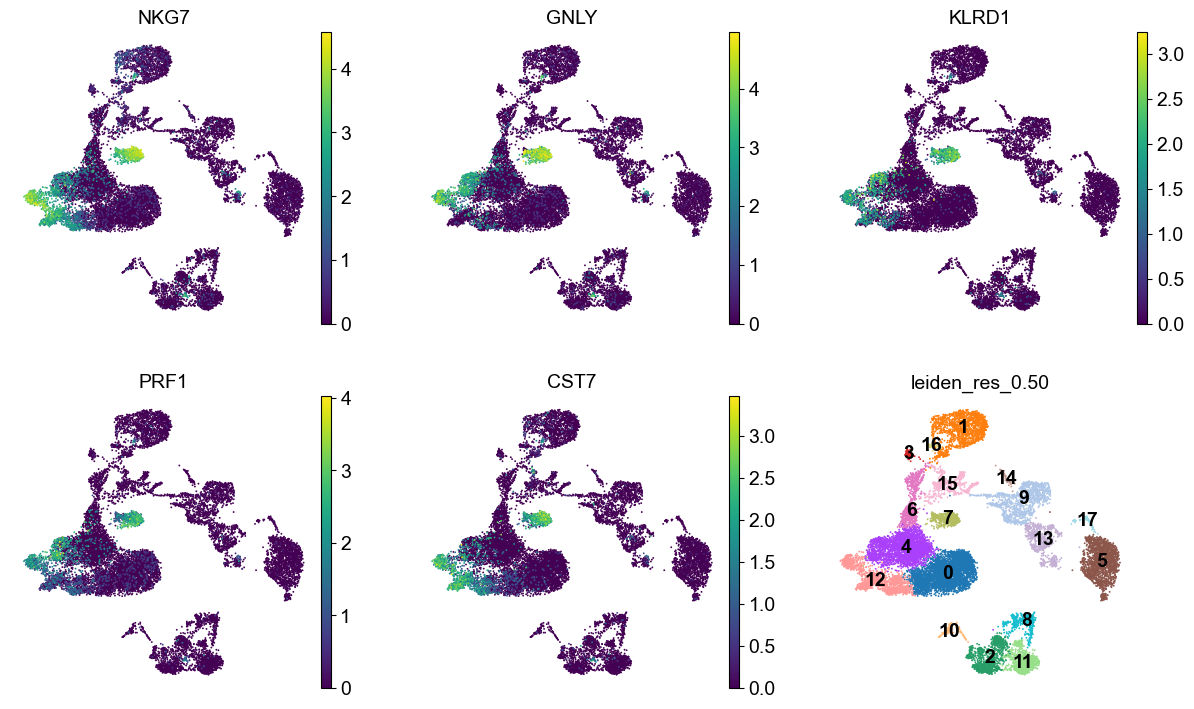

In [53]:
# 举例：将上述的五个差异基因画到UMAP的cluster7中
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
# 将dataframe的names列的值存到dc_cluster_genes中
sc.pl.umap(
    adata,
    color = [*dc_cluster_genes,"leiden_res_0.50"], 
    # *list表示序列解包
    legend_loc = "on data",
    frameon = False, # 隐藏图框
    ncols = 3
)



上述五个基因确实对应cluster7，例如GNLY，在大部分簇类中不表达或在少部分聚类的部分中表达